# Free-living activity and sleep by sex, menopause and estradiol

How do daily activity and sleep measured at the wrist differ between women and men across adult life, between women who still menstruate and women after menopause, and with a single serum estradiol value?

**Data.** NHANES 2013–2014 (US National Center for Health Statistics, public domain): a nationally representative survey. Participants wore an ActiGraph GT3X+ on the non-dominant wrist for up to 9 days; the daily summary file gives the activity sum in MIMS units and the minutes classified as wake wear, sleep wear and non-wear. Serum estradiol was measured once, at the examination. The reproductive health questionnaire asks whether a woman had a period in the past 12 months and, if not, why; the prescription medication file gives current hormone use. **The day of the menstrual cycle was not recorded.** Download with `python download_cycle_data.py nhanes` or set `NHANES` to the folder with the `.xpt` files.

1. **Sample and daily measures.** Adults aged 20 to 79 with at least 4 complete days of wear.
2. **Sex and age.** Daily activity and sleep-classified wear time by sex in 5-year age bands.
3. **Menopause.** Women aged 40 to 59 who menstruated in the past 12 months against women whose periods stopped at menopause, adjusted for age and body mass index.
4. **Estradiol.** Spread of serum estradiol in menstruating women, and its association with daily activity and sleep.

All estimates use the examination sample weights. Confidence intervals treat the 30 strata-by-PSU units of the survey design as clusters, an approximation of the full design-based variance.

In [1]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import Image, display
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

REPO_DIR = Path.cwd()  # run the notebook from the repository folder
NH = Path(os.environ.get("NHANES", "data/nhanes_2013_2014"))
FIG_DIR, RES_DIR = REPO_DIR / "figures", REPO_DIR / "results"
for d in (FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

MIN_WEAR = 20 * 60             # minutes of wake or sleep wear for a complete day
MIN_DAYS = 4
AGES = (20, 79)
HORMONE_DRUGS = ("ESTRADIOL", "ESTROGEN", "NORETHINDRONE", "LEVONORGESTREL", "NORGESTREL", "DROSPIRENONE", "NORGESTIMATE",
                 "DESOGESTREL", "MEDROXYPROGESTERONE", "ETONOGESTREL", "NORELGESTROMIN", "ETHYNODIOL", "PROGESTERONE")
SEED = 7

BLUE, ORANGE, INK, INK2, MUTED, GRIDLINE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#8c8b86", "#e4e3de"


def setup():
    import logging
    from matplotlib import font_manager as fm
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
    avail = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in ["Calibri", "Carlito", "Segoe UI", "Arial"] if f in avail), "DejaVu Sans")
    plt.rcParams.update({
        "font.family": fam, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
        "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
        "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRIDLINE, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
        "lines.linewidth": 1.6, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
        "figure.facecolor": "white", "axes.facecolor": "white"})


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=str(path), width=900))
    print("saved", path.relative_to(REPO_DIR))


setup()

## Sample and daily measures

A day is complete when it has 1440 minutes of data and at least 20 hours classified as wake or sleep wear; the first and last days are partial and drop out. For each person: mean daily activity (thousands of MIMS units), mean daily sleep-classified wear time (hours) and the day-to-day coefficient of variation of activity.

In [2]:
def xpt(name):
    return pd.read_sas(NH / f"{name}.xpt", format="xport", encoding="latin1")


demo, bmx, tst, rhq, rx, pax = (xpt(n) for n in ("DEMO_H", "BMX_H", "TST_H", "RHQ_H", "RXQ_RX_H", "PAXDAY_H"))
pax = pax[(pax.PAXTMD == 1440) & (pax.PAXWWMD + pax.PAXSWMD >= MIN_WEAR) & pax.PAXMTSD.notna()]
person = pax.groupby("SEQN").agg(days=("PAXDAYD", "size"), activity=("PAXMTSD", "mean"), activity_sd=("PAXMTSD", "std"),
                                 sleep=("PAXSWMD", "mean")).reset_index()
person["activity"] /= 1000
person["activity_cv"] = person.activity_sd / 1000 / person.activity
person["sleep"] /= 60

hormone_users = set(rx.SEQN[rx.RXDDRUG.str.contains("|".join(HORMONE_DRUGS), na=False)])
contraception = set(rx.SEQN[(rx[["RXDRSC1", "RXDRSC2", "RXDRSC3"]] == "Z79.3").any(axis=1)
                            | rx.RXDDRUG.str.contains("ETHINYL ESTRADIOL|ETONOGESTREL", na=False)])
A = (demo[["SEQN", "RIAGENDR", "RIDAGEYR", "RIDEXPRG", "WTMEC2YR", "SDMVPSU", "SDMVSTRA"]]
     .merge(bmx[["SEQN", "BMXBMI"]], on="SEQN", how="left").merge(tst[["SEQN", "LBXEST", "LBDESTLC"]], on="SEQN", how="left")
     .merge(rhq[["SEQN", "RHQ031", "RHD043", "RHD280", "RHQ305", "RHQ200"]], on="SEQN", how="left").merge(person, on="SEQN"))
A = A.rename(columns={"RIDAGEYR": "age", "BMXBMI": "bmi", "LBXEST": "estradiol", "WTMEC2YR": "w"})
A["sex"] = A.RIAGENDR.map({1: "M", 2: "F"})
A["cluster"] = A.SDMVSTRA * 10 + A.SDMVPSU
A["hormones"] = A.SEQN.isin(hormone_users)
A = A[A.age.between(*AGES) & (A.days >= MIN_DAYS) & A.bmi.notna() & (A.w > 0)].copy()
print(f"{len(A)} adults aged {AGES[0]} to {AGES[1]} with at least {MIN_DAYS} complete days and a BMI: "
      f"{int((A.sex == 'F').sum())} women, {int((A.sex == 'M').sum())} men; complete days per person: median {A.days.median():.0f}")
print(A.groupby("sex")[["activity", "sleep", "activity_cv"]].median().round(2).to_string())


def wls(formula, data):
    return smf.wls(formula, data=data, weights=data.w).fit(cov_type="cluster", cov_kwds={"groups": data.cluster})


def resid_sd(fit, data):
    """Weighted residual standard deviation, used to express differences in standard deviation units."""
    return float(np.sqrt(np.average(fit.resid ** 2, weights=data.loc[fit.resid.index, "w"])))

3815 adults aged 20 to 79 with at least 4 complete days and a BMI: 2027 women, 1788 men; complete days per person: median 7
     activity  sleep  activity_cv
sex                              
F       13.93   7.70         0.15
M       12.91   7.49         0.17


## Sex and age

Weighted mean in each 5-year age band, with 95% confidence intervals.

In [3]:
A["band"] = (A.age // 5) * 5
BAND = []
for (s, b), g in A.groupby(["sex", "band"]):
    for y in ("activity", "sleep"):
        f = wls(f"{y} ~ 1", g)
        lo, hi = f.conf_int().iloc[0]
        BAND.append(dict(sex=s, band=int(b), measure=y, n=len(g), mean=f.params.iloc[0], lo=lo, hi=hi))
BAND = pd.DataFrame(BAND)
print(BAND.pivot_table(index="band", columns=["measure", "sex"], values="mean").round(2).to_string())
SEXDIFF = {}
for y in ("activity", "sleep", "activity_cv"):
    f = wls(f"{y} ~ C(sex, Treatment('M')) + age + I(age**2)", A)
    t = "C(sex, Treatment('M'))[T.F]"
    SEXDIFF[y] = dict(diff=f.params[t], lo=f.conf_int().loc[t, 0], hi=f.conf_int().loc[t, 1], p=f.pvalues[t])
print("\nwomen minus men, adjusted for age (quadratic):")
for k, v in SEXDIFF.items():
    print(f"  {k:12s} {v['diff']:+.3f} (95% CI {v['lo']:+.3f} to {v['hi']:+.3f}), p = {v['p']:.2g}")

measure activity        sleep      
sex            F      M     F     M
band                               
20         14.59  14.93  8.08  7.37
25         14.98  14.01  7.86  7.77
30         15.15  13.73  7.75  7.73
35         14.89  14.49  7.60  7.52
40         14.53  13.92  7.70  7.38
45         14.70  13.85  7.71  7.58
50         13.41  13.29  8.14  7.60
55         13.80  12.99  7.76  7.79
60         13.31  12.04  8.03  8.30
65         12.96  11.26  8.36  8.48
70         11.48  10.20  8.65  8.81
75         11.02  10.28  8.68  8.84

women minus men, adjusted for age (quadratic):
  activity     +0.798 (95% CI +0.551 to +1.046), p = 2.5e-10
  sleep        +0.119 (95% CI +0.001 to +0.237), p = 0.049
  activity_cv  -0.015 (95% CI -0.022 to -0.007), p = 7.7e-05


## Menopause

Women aged 40 to 59 who had at least one period in the past 12 months, against women without periods for 12 months because of menopause. Women with a hysterectomy or both ovaries removed, women who are pregnant or breastfeeding, and women taking hormones are left out. Differences are adjusted for age and body mass index and given in units of the residual standard deviation, with the raw difference alongside.

In [4]:
W40 = A[(A.sex == "F") & A.age.between(40, 59) & ~A.hormones & (A.RHD280 != 1) & (A.RHQ305 != 1) & (A.RIDEXPRG != 1)
        & (A.RHQ200 != 1)].copy()
W40["status"] = np.select([W40.RHQ031 == 1, (W40.RHQ031 == 2) & (W40.RHD043 == 7)], ["menstruating", "menopause"], "other")
W40 = W40[W40.status != "other"].copy()
W40["meno"] = (W40.status == "menopause").astype(int)
print(W40.groupby("status").age.describe()[["count", "mean", "min", "max"]].round(1).to_string())
MENO = []
for y, lab in (("activity", "Daily activity"), ("sleep", "Sleep-classified wear"), ("activity_cv", "Day-to-day variation")):
    f = wls(f"{y} ~ meno + age + bmi", W40)
    sd = resid_sd(f, W40)
    lo, hi = f.conf_int().loc["meno"]
    MENO.append(dict(measure=y, label=lab, n=int(f.nobs), diff=f.params["meno"], lo=lo, hi=hi, d=f.params["meno"] / sd,
                     d_lo=lo / sd, d_hi=hi / sd, p=f.pvalues["meno"]))
MENO = pd.DataFrame(MENO)
print(MENO.to_string(index=False, float_format=lambda v: f"{v:.3g}"))

              count  mean   min   max
status                               
menopause     199.0  54.3  42.0  59.0
menstruating  304.0  45.3  40.0  57.0
    measure                 label   n    diff      lo     hi       d   d_lo  d_hi     p
   activity        Daily activity 503  -0.248   -1.61   1.11 -0.0713 -0.463  0.32 0.721
      sleep Sleep-classified wear 503  -0.156   -1.15  0.838 -0.0883 -0.649 0.473 0.758
activity_cv  Day-to-day variation 503 -0.0187 -0.0492 0.0117  -0.198 -0.519 0.124 0.228


## Estradiol

Women aged 20 to 54 who had a period in the past 12 months, are not pregnant or breastfeeding and take no hormones. The estradiol value is from one blood sample on an unknown day of the cycle. Values below the limit of detection are kept as reported by NHANES. Associations use log2 estradiol (one unit is a doubling), adjusted for age and body mass index.

In [5]:
E = A[(A.sex == "F") & A.age.between(20, 54) & (A.RHQ031 == 1) & ~A.hormones & (A.RIDEXPRG != 1) & (A.RHQ200 != 1)
      & A.estradiol.notna()].copy()
E["log2_e2"] = np.log2(E.estradiol)
post = W40[(W40.status == "menopause") & W40.estradiol.notna()]
q = E.estradiol.quantile([0.05, 0.5, 0.95])
print(f"menstruating women: n = {len(E)}, estradiol median {q[0.5]:.0f} pg/mL, 5th to 95th percentile {q[0.05]:.0f} to {q[0.95]:.0f} "
      f"({q[0.95] / q[0.05]:.0f}-fold); below detection: {(E.LBDESTLC == 1).mean():.0%}")
print(f"menopause (40 to 59, from above): n = {len(post)}, median {post.estradiol.median():.0f} pg/mL; "
      f"below detection: {(post.LBDESTLC == 1).mean():.0%}")
E2 = []
for y in ("activity", "sleep", "activity_cv"):
    f = wls(f"{y} ~ log2_e2 + age + bmi", E)
    lo, hi = f.conf_int().loc["log2_e2"]
    sd = resid_sd(f, E)
    E2.append(dict(measure=y, n=int(f.nobs), per_doubling=f.params["log2_e2"], lo=lo, hi=hi,
                   d=f.params["log2_e2"] / sd, d_lo=lo / sd, d_hi=hi / sd, p=f.pvalues["log2_e2"]))
E2 = pd.DataFrame(E2)
print(E2.to_string(index=False, float_format=lambda v: f"{v:.3g}"))

menstruating women: n = 679, estradiol median 77 pg/mL, 5th to 95th percentile 11 to 283 (25-fold); below detection: 1%
menopause (40 to 59, from above): n = 176, median 6 pg/mL; below detection: 23%


    measure   n  per_doubling       lo      hi        d    d_lo   d_hi     p
   activity 679         0.113   -0.111   0.338   0.0311 -0.0306 0.0929 0.323
      sleep 679      -0.00571   -0.104  0.0922 -0.00349 -0.0634 0.0564 0.909
activity_cv 679       -0.0026 -0.00887 0.00368  -0.0267 -0.0912 0.0379 0.418


## Figure

**A** Daily activity and **B** sleep-classified wear time by sex and age, weighted means with 95% confidence bands. **C** Differences in daily activity, sleep-classified wear and day-to-day variation (coefficient of variation of daily activity), in standard deviation units and adjusted for age and body mass index: women after menopause against menstruating women aged 40 to 59, and per doubling of estradiol in menstruating women aged 20 to 54. **D** Estradiol and daily activity in menstruating women (log scale), with the weighted regression line adjusted to the mean age and body mass index.

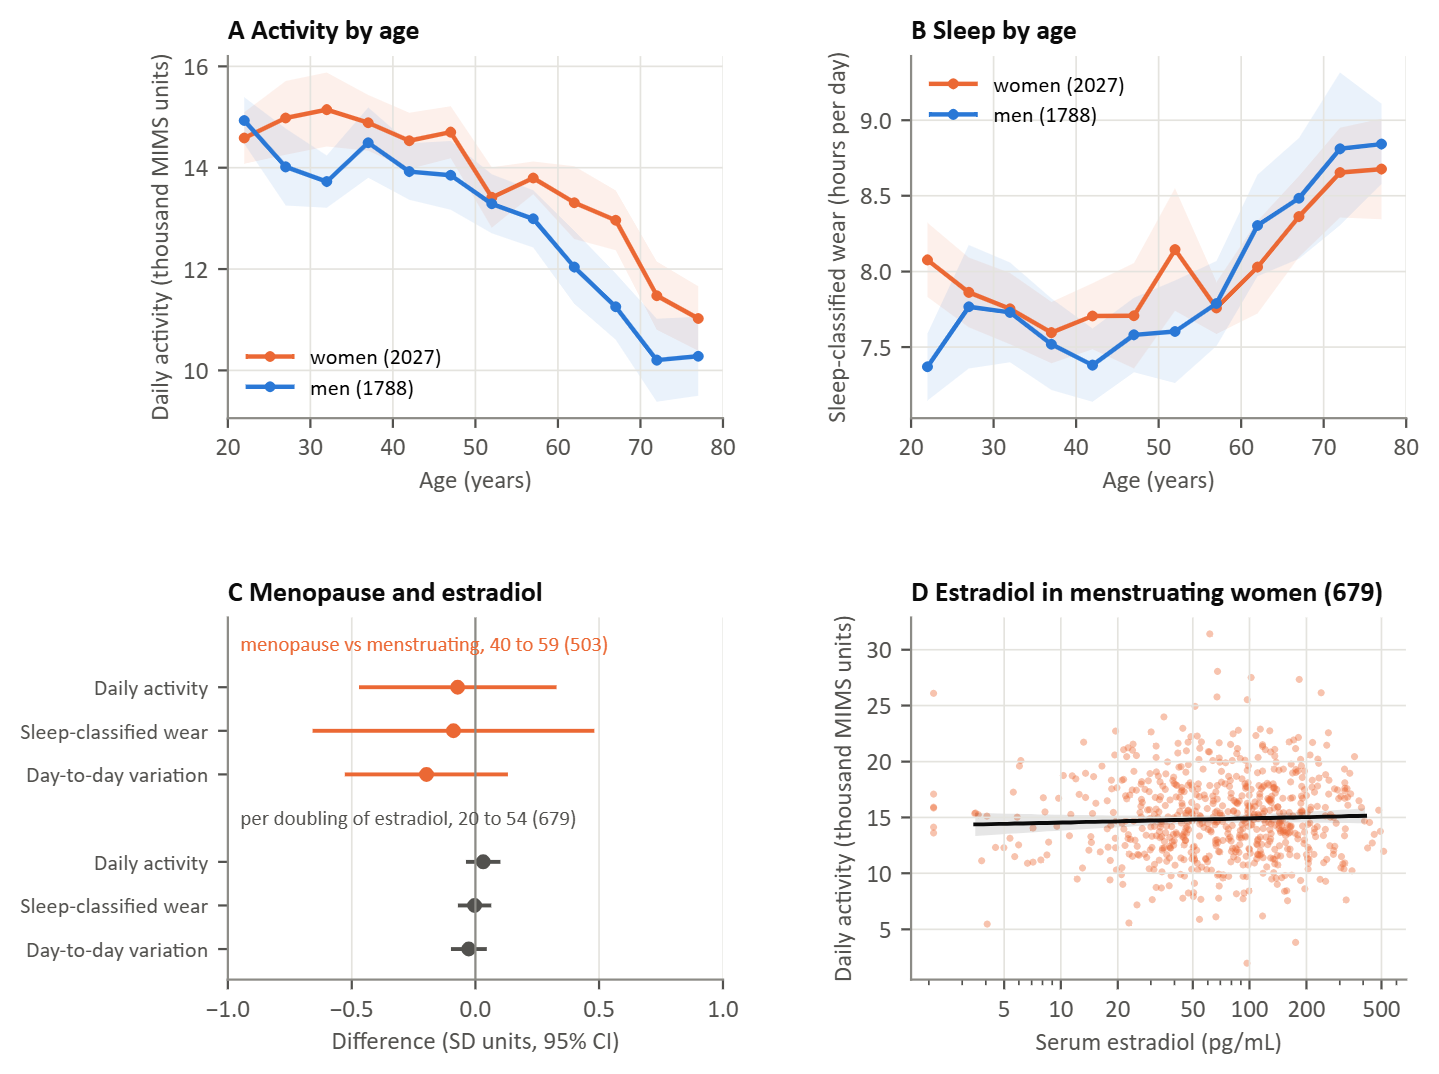

saved figures/nhanes_activity_hormones.png


In [6]:
SCOL = {"F": ORANGE, "M": BLUE}
fig, ax = plt.subplots(2, 2, figsize=(7.6, 6.0))
fig.subplots_adjust(hspace=0.55, wspace=0.38)
for a, y, lab, title in ((ax[0, 0], "activity", "Daily activity (thousand MIMS units)", "A  Activity by age"),
                         (ax[0, 1], "sleep", "Sleep-classified wear (hours per day)", "B  Sleep by age")):
    for s, name in (("F", "women"), ("M", "men")):
        d = BAND[(BAND.sex == s) & (BAND.measure == y)].sort_values("band")
        x = d.band + 2
        a.fill_between(x, d.lo, d.hi, color=SCOL[s], alpha=0.18, lw=0)
        a.plot(x, d["mean"], "o-", ms=3, color=SCOL[s], label=f"{name} ({int((A.sex == s).sum())})")
    a.set(xlabel="Age (years)", ylabel=lab, title=title, xlim=(20, 80))
    a.legend(loc="lower left" if y == "activity" else "upper left")

a = ax[1, 0]
rows = [(f"{r.label}", r.d, r.d_lo, r.d_hi, ORANGE) for r in MENO.itertuples()]
LAB = {"activity": "Daily activity", "sleep": "Sleep-classified wear", "activity_cv": "Day-to-day variation"}
rows += [(LAB[r.measure], r.d, r.d_lo, r.d_hi, INK2) for r in E2.itertuples()]
yy = np.array([6, 5, 4, 2, 1, 0])
for y0, (lab, d, lo, hi, col) in zip(yy, rows):
    a.plot([lo, hi], [y0, y0], color=col, lw=1.4)
    a.plot(d, y0, "o", color=col, ms=4.5)
a.axvline(0, color=MUTED, lw=0.8)
a.set_yticks(yy, [r[0] for r in rows], fontsize=8)
a.text(-0.95, 6.75, f"menopause vs menstruating, 40 to 59 ({int(MENO.n.iloc[0])})", fontsize=7.5, color=ORANGE, va="bottom")
a.text(-0.95, 2.75, f"per doubling of estradiol, 20 to 54 ({int(E2.n.iloc[0])})", fontsize=7.5, color=INK2, va="bottom")
a.set(xlim=(-1, 1), ylim=(-0.7, 7.6), xlabel="Difference (SD units, 95% CI)", title="C  Menopause and estradiol")
a.grid(axis="y", visible=False)

a = ax[1, 1]
a.scatter(E.estradiol, E.activity, s=7, color=ORANGE, alpha=0.45, lw=0)
fe = wls("activity ~ log2_e2 + age + bmi", E)
xs = np.geomspace(E.estradiol.quantile(0.01), E.estradiol.quantile(0.99), 50)
pred = fe.get_prediction(pd.DataFrame({"log2_e2": np.log2(xs), "age": np.average(E.age, weights=E.w),
                                       "bmi": np.average(E.bmi, weights=E.w)})).summary_frame()
a.fill_between(xs, pred.mean_ci_lower, pred.mean_ci_upper, color=INK, alpha=0.12, lw=0)
a.plot(xs, pred["mean"], color=INK, lw=1.4)
a.set_xscale("log")
a.set_xticks([5, 10, 20, 50, 100, 200, 500], ["5", "10", "20", "50", "100", "200", "500"])
a.set(xlabel="Serum estradiol (pg/mL)", ylabel="Daily activity (thousand MIMS units)",
      title=f"D  Estradiol in menstruating women ({len(E)})")
save(fig, "nhanes_activity_hormones.png")

## Results file

In [7]:
def clean(v):
    if isinstance(v, dict):
        return {k: clean(x) for k, x in v.items()}
    if isinstance(v, (list, tuple, np.ndarray)):
        return [clean(x) for x in v]
    if isinstance(v, (np.floating, float)):
        return None if np.isnan(v) else float(f"{float(v):.4g}")
    if isinstance(v, np.integer):
        return int(v)
    return v


RES = {
    "dataset": "NHANES 2013-2014", "n_adults": len(A), "n_women": int((A.sex == "F").sum()), "n_men": int((A.sex == "M").sum()),
    "median_by_sex": clean(A.groupby("sex")[["activity", "sleep", "activity_cv"]].median().to_dict("index")),
    "by_age_band": clean(BAND.to_dict("records")), "women_minus_men_age_adjusted": clean(SEXDIFF),
    "menopause": {"n": clean(W40.status.value_counts().to_dict()), "results": clean(MENO.drop(columns="label").to_dict("records"))},
    "estradiol": {"n": len(E), "median": clean(q[0.5]), "p5": clean(q[0.05]), "p95": clean(q[0.95]),
                  "below_lod": clean((E.LBDESTLC == 1).mean()), "menopause_median": clean(post.estradiol.median()),
                  "results": clean(E2.to_dict("records"))},
}
(RES_DIR / "nhanes_activity_hormones.json").write_text(json.dumps(RES, indent=1))
print("saved results/nhanes_activity_hormones.json")

saved results/nhanes_activity_hormones.json
